# Airbnb Prices in European Cities: Full Pipeline (Bronze → Silver → Gold)
**Run all cells.** Put this notebook in the same folder as the dataset `.zip` (or a folder named `raw/` containing the 20 CSVs).
Outputs: `bronze/`, `silver/`, `gold/` folders with CSVs. For Power BI / Tableau, load the files in `gold/`.

In [1]:
import os, glob, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200)

# ---- locate the raw CSVs (auto-extracts a .zip if found) ----
RAW = 'raw'
if not glob.glob(os.path.join(RAW, '**', '*.csv'), recursive=True):
    zips = glob.glob('*.zip')
    assert zips, 'Put the dataset .zip next to this notebook, or the CSVs in a folder called raw/'
    with zipfile.ZipFile(zips[0]) as z: z.extractall(RAW)
CSVS = sorted(glob.glob(os.path.join(RAW, '**', '*.csv'), recursive=True))
print(len(CSVS), 'CSV files found')
for d in ('bronze','silver','gold'): os.makedirs(d, exist_ok=True)

20 CSV files found


## 1. Bronze: raw data, untouched, with lineage columns

In [2]:
frames = []
for f in CSVS:
    name = os.path.basename(f)
    city, daytype = name.replace('.csv','').split('_')
    df = pd.read_csv(f)
    df['source_file'], df['city'], df['day_type'] = name, city, daytype
    df['ingested_at'] = pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')
    frames.append(df)
bronze = pd.concat(frames, ignore_index=True)
bronze.to_csv('bronze/bronze_listings.csv', index=False)
print('Bronze rows:', len(bronze)); bronze.head()

Bronze rows: 51707


,Unnamed: 0,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,...,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat,source_file,city,day_type,ingested_at
0,0,194.033698,Private room,False,True,2.0,False,1,0,10.0,...,78.690379,4.166708,98.253896,6.846473,4.90569,52.41772,amsterdam_weekdays.csv,amsterdam,weekdays,2026-10-22 18:00:40
1,1,344.245776,Private room,False,True,4.0,False,0,0,8.0,...,631.176378,33.421209,837.280757,58.342928,4.90005,52.37432,amsterdam_weekdays.csv,amsterdam,weekdays,2026-10-22 18:00:40
2,2,264.101422,Private room,False,True,2.0,False,0,1,9.0,...,75.275877,3.985908,95.386955,6.646700,4.97512,52.36103,amsterdam_weekdays.csv,amsterdam,weekdays,2026-10-22 18:00:40
3,3,433.529398,Private room,False,True,4.0,False,0,1,9.0,...,493.272534,26.119108,875.033098,60.973565,4.89417,52.37663,amsterdam_weekdays.csv,amsterdam,weekdays,2026-10-22 18:00:40
4,4,485.552926,Private room,False,True,2.0,True,0,0,10.0,...,552.830324,29.272733,815.305740,56.811677,4.90051,52.37508,amsterdam_weekdays.csv,amsterdam,weekdays,2026-10-22 18:00:40


## 2. Silver: cleaned, typed and enriched

In [3]:
COUNTRY = {'amsterdam':'Netherlands','athens':'Greece','barcelona':'Spain','berlin':'Germany','budapest':'Hungary',
           'lisbon':'Portugal','london':'United Kingdom','paris':'France','rome':'Italy','vienna':'Austria'}
s = bronze.drop(columns=['ingested_at']).rename(columns={
    'Unnamed: 0':'source_row_id','realSum':'total_price_2nights','host_is_superhost':'is_superhost',
    'multi':'is_multi_listing_host','biz':'is_business_listing','guest_satisfaction_overall':'guest_satisfaction',
    'dist':'dist_city_center_km','metro_dist':'dist_metro_km','lng':'longitude','lat':'latitude'})
s['city'] = s.city.str.strip().str.title(); s['day_type'] = s.day_type.str.title()
s['room_type'] = s.room_type.str.strip(); s['country'] = s.city.str.lower().map(COUNTRY)
for c in ['room_shared','room_private','is_superhost','is_multi_listing_host','is_business_listing']: s[c] = s[c].astype(bool)
s['person_capacity'] = s.person_capacity.astype(int)

n0 = len(s)
s = s.drop_duplicates(subset=[c for c in s.columns if c not in ('source_row_id','source_file')])
s = s[(s.total_price_2nights>0) & s.latitude.between(-90,90) & s.longitude.between(-180,180)
      & s.guest_satisfaction.between(0,100) & s.cleanliness_rating.between(0,10)]
print(f'Removed {n0-len(s)} duplicate/invalid rows')

s['price_per_night'] = (s.total_price_2nights/2).round(2)
s['price_per_person_night'] = (s.price_per_night/s.person_capacity).round(2)
s['is_studio'] = s.bedrooms==0
s['price_per_bedroom_night'] = np.where(s.bedrooms>0,(s.price_per_night/s.bedrooms).round(2),np.nan)
q1 = s.groupby('city').price_per_night.transform(lambda x:x.quantile(.25))
q3 = s.groupby('city').price_per_night.transform(lambda x:x.quantile(.75))
s['is_price_outlier'] = s.price_per_night > q3 + 3*(q3-q1)
s['price_band'] = pd.cut(s.price_per_night,[0,75,150,300,np.inf],labels=['Budget (<75)','Mid (75-150)','Upper (150-300)','Luxury (300+)']).astype(str)
s['distance_band'] = pd.cut(s.dist_city_center_km,[-.01,1,3,6,np.inf],labels=['0-1 km','1-3 km','3-6 km','6+ km']).astype(str)
s['satisfaction_band'] = pd.cut(s.guest_satisfaction,[-.01,80,90,95,100],labels=['<=80','81-90','91-95','96-100']).astype(str)
s.insert(0,'listing_id',np.arange(1,len(s)+1))
silver = s.reset_index(drop=True)
silver.to_csv('silver/silver_listings.csv', index=False)
print('Silver rows:', len(silver), '| outliers flagged:', int(silver.is_price_outlier.sum())); silver.head()

Removed 0 duplicate/invalid rows


Silver rows: 51707 | outliers flagged: 826


,listing_id,source_row_id,total_price_2nights,room_type,room_shared,room_private,person_capacity,is_superhost,is_multi_listing_host,is_business_listing,...,day_type,country,price_per_night,price_per_person_night,is_studio,price_per_bedroom_night,is_price_outlier,price_band,distance_band,satisfaction_band
0,1,0,194.033698,Private room,False,True,2,False,True,False,...,Weekdays,Netherlands,97.02,48.51,False,97.02,False,Mid (75-150),3-6 km,91-95
1,2,1,344.245776,Private room,False,True,4,False,False,False,...,Weekdays,Netherlands,172.12,43.03,False,172.12,False,Upper (150-300),0-1 km,81-90
2,3,2,264.101422,Private room,False,True,2,False,False,True,...,Weekdays,Netherlands,132.05,66.03,False,132.05,False,Mid (75-150),3-6 km,81-90
3,4,3,433.529398,Private room,False,True,4,False,False,True,...,Weekdays,Netherlands,216.76,54.19,False,108.38,False,Upper (150-300),0-1 km,81-90
4,5,4,485.552926,Private room,False,True,2,True,False,False,...,Weekdays,Netherlands,242.78,121.39,False,242.78,False,Upper (150-300),0-1 km,96-100


## 3. Gold: star schema + dashboard-ready aggregates

In [4]:
g = silver.copy()
dim_city = g.groupby(['city','country']).agg(center_lat=('latitude','mean'),center_lng=('longitude','mean')).reset_index().round(5)
dim_city.insert(0,'city_key',range(1,len(dim_city)+1))
dim_room = pd.DataFrame({'room_type':sorted(g.room_type.unique())}); dim_room.insert(0,'room_type_key',range(1,len(dim_room)+1))
dim_day = pd.DataFrame({'day_type':['Weekdays','Weekends']}); dim_day.insert(0,'day_type_key',[1,2])

fact = g.merge(dim_city[['city_key','city']],on='city').merge(dim_room,on='room_type').merge(dim_day,on='day_type')
fact_cols = ['listing_id','city_key','room_type_key','day_type_key','total_price_2nights','price_per_night','price_per_person_night',
 'price_per_bedroom_night','person_capacity','bedrooms','is_studio','is_superhost','is_multi_listing_host','is_business_listing',
 'cleanliness_rating','guest_satisfaction','dist_city_center_km','dist_metro_km','attr_index','attr_index_norm','rest_index',
 'rest_index_norm','latitude','longitude','price_band','distance_band','satisfaction_band','is_price_outlier']
fact[fact_cols].to_csv('gold/fact_listings.csv',index=False)
dim_city.to_csv('gold/dim_city.csv',index=False); dim_room.to_csv('gold/dim_room_type.csv',index=False); dim_day.to_csv('gold/dim_day_type.csv',index=False)
g.to_csv('gold/gold_listings_wide.csv',index=False)      # one flat table: easiest for a quick dashboard

core = g[~g.is_price_outlier]                              # aggregates exclude extreme outliers
def agg(by):
    return (core.groupby(by).agg(listings=('listing_id','count'),avg_price_night=('price_per_night','mean'),
        median_price_night=('price_per_night','median'),avg_price_person_night=('price_per_person_night','mean'),
        avg_satisfaction=('guest_satisfaction','mean'),avg_cleanliness=('cleanliness_rating','mean'),
        avg_dist_center_km=('dist_city_center_km','mean'),superhost_pct=('is_superhost','mean'))
        .assign(superhost_pct=lambda d:d.superhost_pct*100).round(2).reset_index())
agg_city = agg('city').merge(dim_city[['city','country']],on='city').sort_values('avg_price_night',ascending=False)
agg_city.to_csv('gold/agg_city.csv',index=False)
for name,by in {'agg_city_daytype':['city','day_type'],'agg_city_roomtype':['city','room_type'],'agg_roomtype':'room_type',
                'agg_superhost':['is_superhost'],'agg_city_distance':['city','distance_band'],
                'agg_city_capacity':['city','person_capacity'],'agg_city_priceband':['city','price_band']}.items():
    agg(by).to_csv(f'gold/{name}.csv',index=False)
num = ['price_per_night','person_capacity','bedrooms','cleanliness_rating','guest_satisfaction','dist_city_center_km',
       'dist_metro_km','attr_index_norm','rest_index_norm','is_superhost','is_business_listing','is_multi_listing_host']
corr = core[num].astype(float).corr()['price_per_night'].drop('price_per_night').round(3)
corr.rename('correlation_with_price').reset_index().rename(columns={'index':'feature'}).sort_values('correlation_with_price',key=abs,ascending=False).to_csv('gold/agg_price_correlation.csv',index=False)
print(sorted(os.listdir('gold'))); agg_city

['agg_city.csv', 'agg_city_capacity.csv', 'agg_city_daytype.csv', 'agg_city_distance.csv', 'agg_city_priceband.csv', 'agg_city_roomtype.csv', 'agg_price_correlation.csv', 'agg_roomtype.csv', 'agg_superhost.csv', 'dim_city.csv', 'dim_day_type.csv', 'dim_room_type.csv', 'fact_listings.csv', 'gold_listings_wide.csv']


,city,listings,avg_price_night,median_price_night,avg_price_person_night,avg_satisfaction,avg_cleanliness,avg_dist_center_km,superhost_pct,country
0,Amsterdam,2047,269.69,227.43,99.39,94.46,9.46,2.85,28.53,Netherlands
7,Paris,6558,183.07,156.47,66.08,91.97,9.26,3.00,14.00,France
6,London,9821,162.81,128.88,58.47,90.59,9.17,5.37,15.74,United Kingdom
2,Barcelona,2766,130.91,102.99,51.34,91.12,9.29,2.12,18.15,Spain
5,Lisbon,5727,117.31,111.98,37.27,91.07,9.37,1.96,21.49,Portugal
9,Vienna,3494,112.48,103.78,36.43,93.73,9.47,3.15,28.45,Austria
3,Berlin,2428,111.45,93.83,43.18,94.34,9.46,5.28,25.74,Germany
8,Rome,8929,98.99,91.06,31.82,93.10,9.51,3.04,32.64,Italy
4,Budapest,3933,82.19,75.67,25.44,94.60,9.48,1.88,38.29,Hungary
1,Athens,5178,70.48,63.86,20.69,94.99,9.64,1.82,42.95,Greece


## 4. Validation (all should be ✅)

In [5]:
def check(n,c): print('✅' if c else '❌', n)
check('Bronze has 20 source files', bronze.source_file.nunique()==20)
check('Silver rows == Bronze rows', len(silver)==len(bronze))
check('No nulls in key columns', silver[['price_per_night','city','room_type','guest_satisfaction','latitude','longitude']].isna().sum().sum()==0)
check('listing_id unique', silver.listing_id.is_unique)
check('Prices > 0', (silver.price_per_night>0).all())
check('Fact rows == Silver rows', len(fact)==len(silver))
check('Fact keys resolve to dimensions', fact.city_key.isin(dim_city.city_key).all() and fact.room_type_key.isin(dim_room.room_type_key).all())
check('Aggregates reconcile (listings == non-outliers)', agg_city.listings.sum()==len(core))

✅ Bronze has 20 source files
✅ Silver rows == Bronze rows
✅ No nulls in key columns
✅ listing_id unique
✅ Prices > 0
✅ Fact rows == Silver rows
✅ Fact keys resolve to dimensions
✅ Aggregates reconcile (listings == non-outliers)


## 5. Quick preview of dashboard visuals

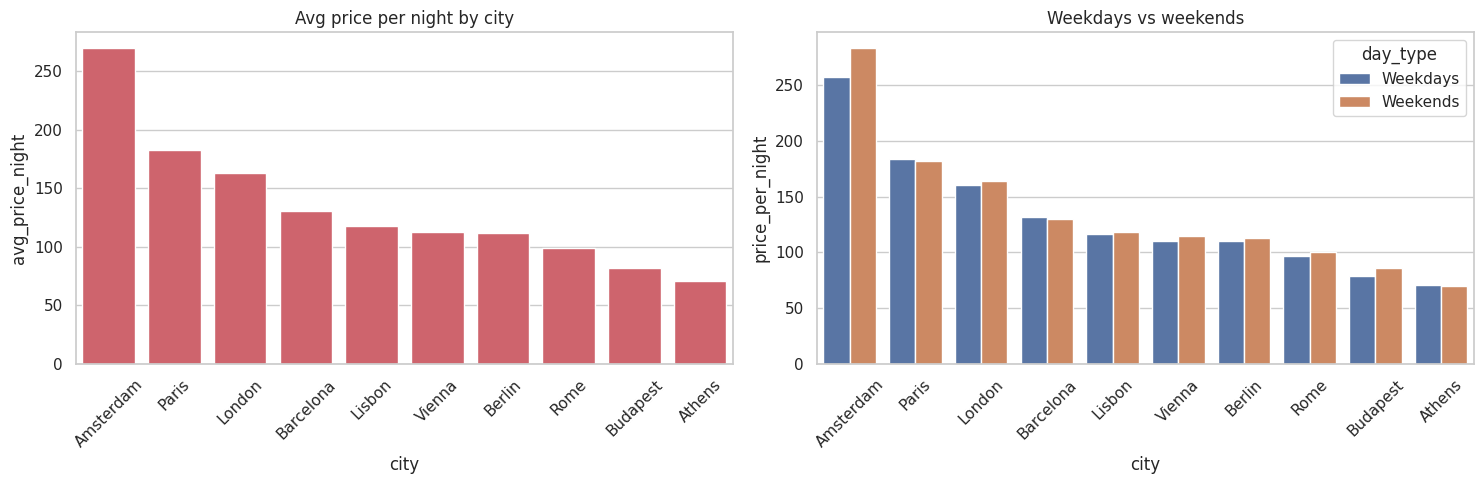

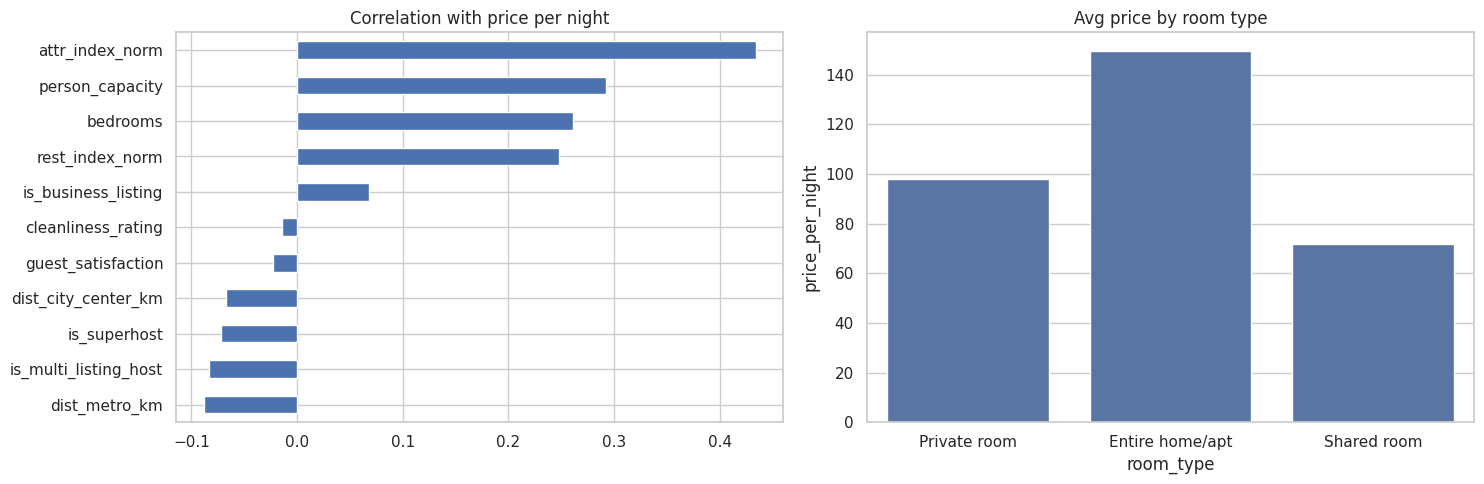

In [6]:
fig,ax=plt.subplots(1,2,figsize=(15,5))
order=agg_city.city
sns.barplot(data=agg_city,x='city',y='avg_price_night',ax=ax[0],color='#e0525e'); ax[0].set_title('Avg price per night by city'); ax[0].tick_params(axis='x',rotation=45)
sns.barplot(data=core,x='city',y='price_per_night',hue='day_type',order=order,errorbar=None,ax=ax[1]); ax[1].set_title('Weekdays vs weekends'); ax[1].tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,2,figsize=(15,5))
corr.sort_values().plot(kind='barh',ax=ax[0],title='Correlation with price per night')
sns.barplot(data=core,x='room_type',y='price_per_night',errorbar=None,ax=ax[1]); ax[1].set_title('Avg price by room type')
plt.tight_layout(); plt.show()

## Next: build the dashboard
Load from `gold/` into Power BI / Tableau / Excel:
- **Star schema:** `fact_listings` + `dim_city`, `dim_room_type`, `dim_day_type` (relate on the `*_key` columns).
- **Or one flat table:** `gold_listings_wide.csv`.
- **Ready aggregates:** `agg_city`, `agg_city_daytype`, `agg_city_roomtype`, `agg_superhost`, `agg_city_distance`, `agg_price_correlation`...

Filter out `is_price_outlier = True` for averages.